# BÀI TẬP XÁC SUẤT RỜI RẠC VỚI SCIPY (MAT1052)
**Bài làm:** Bài 24, Bài 25, Bài 27


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, hypergeom


---
## Bài 24
**Đề bài:** Dùng `scipy.stats.binom` để lập hàm khối xác suất của số mặt ngửa khi tung đồng xu cân đối bốn lần, rồi vẽ biểu đồ của hàm khối xác suất. Nộp mã Python và biểu đồ.

**Giải thích lý thuyết:**
- Tung đồng xu cân đối 4 lần: $n = 4$, xác suất ra mặt ngửa $p = 0.5$.
- Gọi $X$ là số mặt ngửa, thì $X \sim \text{Binomial}(n = 4, p = 0.5)$.
- $X$ nhận các giá trị $k \in \{0, 1, 2, 3, 4\}$.
- Công thức hàm khối xác suất (PMF): $P(X = k) = \binom{4}{k} (0.5)^4$.


Hàm khối xác suất P(X = k):
P(X = 0) = 0.0625
P(X = 1) = 0.2500
P(X = 2) = 0.3750
P(X = 3) = 0.2500
P(X = 4) = 0.0625


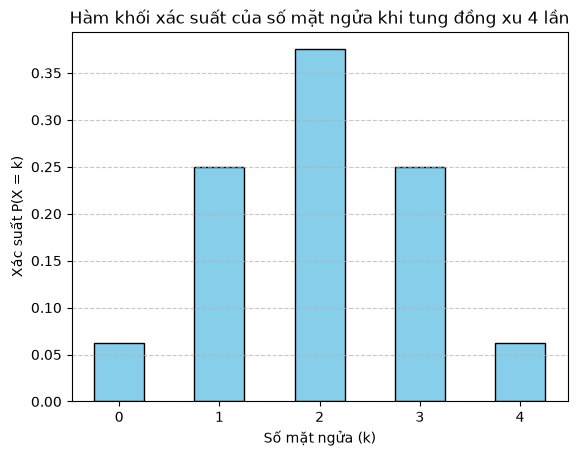

In [2]:
# 1. Khai báo tham số
n = 4       # Số lần tung
p = 0.5     # Xác suất ra mặt ngửa mỗi lần
k = np.array([0, 1, 2, 3, 4])  # Các giá trị có thể có của số mặt ngửa

# 2. Lập hàm khối xác suất (PMF) bằng scipy.stats.binom
pmf = binom.pmf(k, n, p)

# In giá trị xác suất lý thuyết
print("Hàm khối xác suất P(X = k):")
for ki, prob in zip(k, pmf):
    print(f"P(X = {ki}) = {prob:.4f}")

# 3. Vẽ biểu đồ hàm khối xác suất
plt.bar(k, pmf, color='skyblue', edgecolor='black', width=0.5)
plt.title("Hàm khối xác suất của số mặt ngửa khi tung đồng xu 4 lần")
plt.xlabel("Số mặt ngửa (k)")
plt.ylabel("Xác suất P(X = k)")
plt.xticks(k)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


---
## Bài 25
**Đề bài:** Dùng Python mô phỏng 500 lần và 10 000 lần thí nghiệm tung đồng xu cân đối bốn lần. Với mỗi số lần mô phỏng, hãy vẽ biểu đồ tần suất thực nghiệm của số mặt ngửa và so sánh với biểu đồ lý thuyết ở Bài 24.

**Nhận xét:**
- Khi số lần mô phỏng nhỏ ($N = 500$), tần suất thực nghiệm có dao động và lệch so với lý thuyết do yếu tố ngẫu nhiên.
- Khi tăng số lần mô phỏng lên lớn ($N = 10\,000$), tần suất thực nghiệm bám rất sát xác suất lý thuyết. Điều này minh họa cho **Định luật số lớn**.


k | Lý thuyết | Thực nghiệm (500 lần) | Thực nghiệm (10 000 lần)
------------------------------------------------------------
0 | 0.0625    | 0.0720                | 0.0632
1 | 0.2500    | 0.2460                | 0.2540
2 | 0.3750    | 0.3600                | 0.3806
3 | 0.2500    | 0.2480                | 0.2408
4 | 0.0625    | 0.0740                | 0.0614


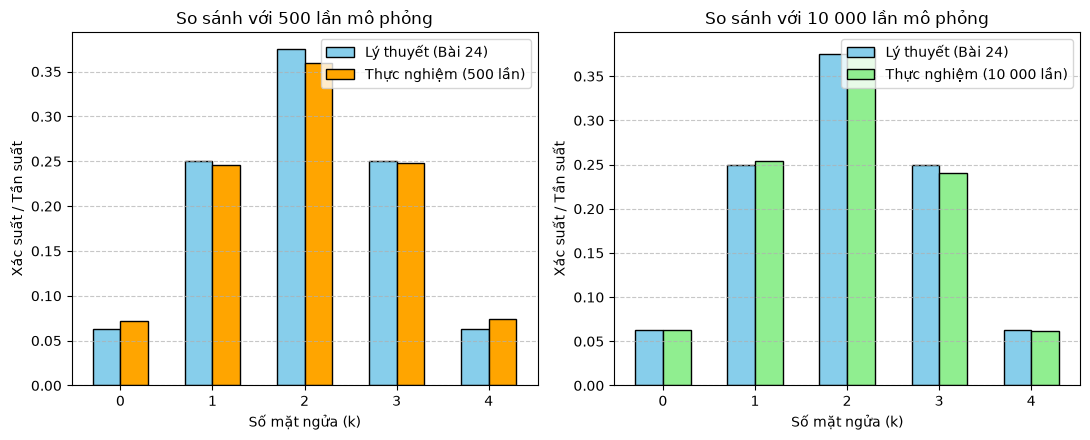

In [3]:
# 1. Mô phỏng 500 lần và 10 000 lần bằng binom.rvs
samples_500 = binom.rvs(n=4, p=0.5, size=500, random_state=42)
samples_10000 = binom.rvs(n=4, p=0.5, size=10000, random_state=42)

# 2. Tính tần suất thực nghiệm của từng giá trị k (từ 0 đến 4)
freq_500 = [np.mean(samples_500 == i) for i in k]
freq_10000 = [np.mean(samples_10000 == i) for i in k]

# In bảng so sánh
print("k | Lý thuyết | Thực nghiệm (500 lần) | Thực nghiệm (10 000 lần)")
print("-" * 60)
for i in range(len(k)):
    print(f"{k[i]} | {pmf[i]:.4f}    | {freq_500[i]:.4f}                | {freq_10000[i]:.4f}")

# 3. Vẽ biểu đồ so sánh giữa thực nghiệm và lý thuyết
plt.figure(figsize=(11, 4.5))

# Đồ thị 1: 500 lần
plt.subplot(1, 2, 1)
plt.bar(k - 0.15, pmf, width=0.3, label='Lý thuyết (Bài 24)', color='skyblue', edgecolor='black')
plt.bar(k + 0.15, freq_500, width=0.3, label='Thực nghiệm (500 lần)', color='orange', edgecolor='black')
plt.title("So sánh với 500 lần mô phỏng")
plt.xlabel("Số mặt ngửa (k)")
plt.ylabel("Xác suất / Tần suất")
plt.xticks(k)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Đồ thị 2: 10 000 lần
plt.subplot(1, 2, 2)
plt.bar(k - 0.15, pmf, width=0.3, label='Lý thuyết (Bài 24)', color='skyblue', edgecolor='black')
plt.bar(k + 0.15, freq_10000, width=0.3, label='Thực nghiệm (10 000 lần)', color='lightgreen', edgecolor='black')
plt.title("So sánh với 10 000 lần mô phỏng")
plt.xlabel("Số mặt ngửa (k)")
plt.ylabel("Xác suất / Tần suất")
plt.xticks(k)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


---
## Bài 27
**Đề bài:** Cho hai đoạn mã dưới đây, trong đó mục tiêu là mô phỏng số sản phẩm không đạt chuẩn khi chọn ngẫu nhiên 5 sản phẩm không hoàn lại từ lô 20 sản phẩm gồm 6 sản phẩm không đạt chuẩn.
```python
from scipy.stats import hypergeom
x1 = hypergeom.rvs(M=20, n=6, N=5, size=10_000, random_state=2026)
x2 = hypergeom.rvs(M=20, n=14, N=5, size=10_000, random_state=2026)
```
Hãy:
1. Xác định đoạn mã nào mô phỏng đúng đại lượng cần xét.
2. Giải thích ý nghĩa ba tham số $M, n, N$ của hàm `hypergeom.rvs`.
3. Sửa đoạn mã sai.
4. Dùng đoạn mã đúng để ước lượng $P(X = 2)$; sau đó so sánh với giá trị lý thuyết từ phân phối siêu bội.

---

### Trả lời lý thuyết:
1. **Đoạn mã đúng:**
   - **`x1` là đoạn mã đúng**, vì ta cần đếm số sản phẩm **không đạt chuẩn**, mà trong lô có 6 sản phẩm không đạt chuẩn nên $n = 6$.
   - **`x2` là đoạn mã sai**, vì truyền $n = 14$ (số sản phẩm đạt chuẩn) nên `x2` mô phỏng số sản phẩm đạt chuẩn.
2. **Ý nghĩa 3 tham số của hàm `hypergeom.rvs(M, n, N, ...)`:**
   - `M = 20`: Tổng số sản phẩm trong lô (kích thước tổng thể).
   - `n = 6`: Số sản phẩm không đạt chuẩn có trong lô (số phần tử loại quan tâm trong tổng thể).
   - `N = 5`: Số sản phẩm lấy ra không hoàn lại (cỡ mẫu).
3. **Sửa đoạn mã sai:**
   - Sửa lại tham số $n = 6$:
     `x2_sua = hypergeom.rvs(M=20, n=6, N=5, size=10_000, random_state=2026)`
   - Hoặc lấy bù: `x2_sua = 5 - x2` (vì tổng số SP lấy ra là 5).
4. **Công thức lý thuyết:**
   $$P(X = 2) = \frac{\binom{6}{2} \binom{14}{3}}{\binom{20}{5}} = \frac{15 \times 364}{15504} = \frac{455}{1292} \approx 0.352167$$


In [4]:
# 1. Chạy đoạn mã cho trong đề bài
x1 = hypergeom.rvs(M=20, n=6, N=5, size=10_000, random_state=2026)
x2 = hypergeom.rvs(M=20, n=14, N=5, size=10_000, random_state=2026)

# Sửa đoạn mã sai (đổi n=14 thành n=6)
x2_sua = hypergeom.rvs(M=20, n=6, N=5, size=10_000, random_state=2026)

# 2. Dùng đoạn mã đúng x1 để ước lượng P(X = 2)
p_uoc_luong = np.mean(x1 == 2)

# 3. Tính giá trị lý thuyết bằng hàm hypergeom.pmf
p_ly_thuyet = hypergeom.pmf(k=2, M=20, n=6, N=5)

# 4. In kết quả và so sánh
print(f"Ước lượng thực nghiệm từ x1 : {p_uoc_luong:.6f}")
print(f"Giá trị lý thuyết P(X = 2)   : {p_ly_thuyet:.6f} (phân số: 455/1292)")
print(f"Sai số tuyệt đối             : {abs(p_uoc_luong - p_ly_thuyet):.6f}")


Ước lượng thực nghiệm từ x1 : 0.344700
Giá trị lý thuyết P(X = 2)   : 0.352167 (phân số: 455/1292)
Sai số tuyệt đối             : 0.007467
